<a href="https://colab.research.google.com/github/ny6in/AIML/blob/main/logregression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (2034, 53)

First 5 rows:
   Rk             Player  Nation Pos         Squad                Comp   Age  \
0   1   Brenden Aaronson  us USA  MF  Leeds United  eng Premier League  25.0   
1   2      Haitam Abaida  ma MAR  FW        Málaga          es La Liga  24.0   
2   3     James Abankwah  ie IRL  DF       Udinese          it Serie A  22.0   
3   4  Keyliane Abdallah  fr FRA  FW     Marseille          fr Ligue 1  20.0   
4   5   Hamza Abdelkarim  eg EGY  FW     Barcelona          es La Liga  18.0   

     Born  MP  Starts  ...  Save%   W   D   L  CS  CS%  PKatt_stats_keeper  \
0  2000.0   3       2  ...    NaN NaN NaN NaN NaN  NaN                 NaN   
1  2002.0   2       0  ...    NaN NaN NaN NaN NaN  NaN                 NaN   
2  2004.0   3       3  ...    NaN NaN NaN NaN NaN  NaN                 NaN   
3  2006.0   4       0  ...    NaN NaN NaN NaN NaN  NaN                 NaN   
4  2008.0   1       0  ...    NaN NaN NaN NaN NaN  NaN                 NaN   

   PKA  P

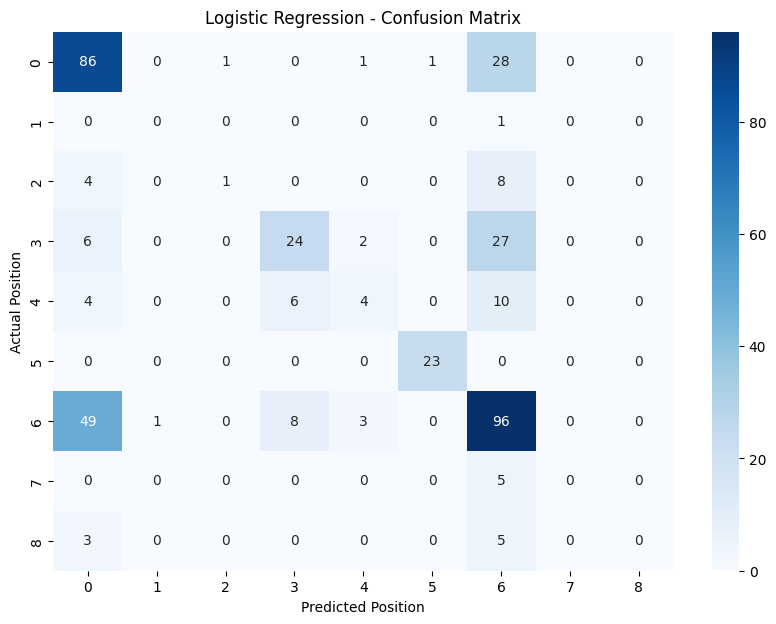

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/content/players_data.csv.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())



print("\nMissing Values:")
print(df.isnull().sum())



y = df["Pos"]


X = df.select_dtypes(include=np.number)


if "Rk" in X.columns:
    X = X.drop("Rk", axis=1)




X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])




model = Pipeline([


    ("imputer", SimpleImputer(strategy="median")),


    ("scaler", StandardScaler()),


    ("logistic_regression",
     LogisticRegression(
         max_iter=2000,
         random_state=42
     ))
])



model.fit(X_train, y_train)

print("\nLogistic Regression model trained successfully!")




y_pred = model.predict(X_test)



accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:")
print(accuracy)

print("\nAccuracy Percentage:")
print(accuracy * 100, "%")




print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))




cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Position")
plt.ylabel("Actual Position")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()